# UCI Cleveland Heart Disease: Multi-Class Preprocessing & In-Depth EDA (No SMOTE)
## Comparative Data Analysis & Visualization Before and After Preprocessing

### Overview:
This notebook provides a thorough **exploratory data analysis (EDA)**, **statistical characterization**, and **leak-free preprocessing pipeline** on the gold-standard **UCI Cleveland Heart Disease dataset** for **multi-class coronary artery disease (CAD) severity classification**.

### Key Principles of this Notebook:
1. **Multi-Class Severity Spectrum (Classes 0 to 4)**: Preserves the authentic 5 clinical severity levels (0 = No Disease, 1 = Mild CAD, 2 = Moderate CAD, 3 = Severe CAD, 4 = Critical CAD) without artificial binary collapsing.
2. **Strictly NO SMOTE**: Eliminates synthetic minority oversampling. Real medical data is inherently imbalanced; training without SMOTE evaluates the true capability of classifiers on natural clinical distributions without synthetic interpolation artifacts or boundary distortion.
3. **Comprehensive Before vs. After Analysis**: Detailed side-by-side visualizations comparing distributions, correlations, missingness, and feature spaces before and after each preprocessing transformation.
4. **Zero-Leakage Guarantee**: Stratified 80/20 train-test split executed before any transformation; imputers, one-hot encoders, and scalers are fitted strictly on `X_train` and applied to `X_test`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.decomposition import PCA

# Plotting configuration
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

## 1. Dataset Ingestion & Clinical Schema Definition

We load all 303 patient records from `datasets/heart+disease/processed.cleveland.data`. Missing values (`?`) are parsed as `NaN`.

In [2]:
COLUMNS = [
    'age',       # Age in years (Continuous)
    'sex',       # Sex: 1 = Male, 0 = Female (Binary)
    'cp',        # Chest pain type: 1 = typ angina, 2 = atyp angina, 3 = non-anginal, 4 = asympt (Nominal)
    'trestbps',  # Resting blood pressure in mm Hg (Continuous)
    'chol',      # Serum cholesterol in mg/dl (Continuous)
    'fbs',       # Fasting blood sugar > 120 mg/dl: 1 = true, 0 = false (Binary)
    'restecg',   # Resting ECG: 0 = normal, 1 = ST-T wave abn, 2 = LV hypertrophy (Nominal)
    'thalach',   # Maximum heart rate achieved (Continuous)
    'exang',     # Exercise induced angina: 1 = yes, 0 = no (Binary)
    'oldpeak',   # ST depression induced by exercise relative to rest (Continuous)
    'slope',     # Slope of peak exercise ST segment: 1 = up, 2 = flat, 3 = down (Ordered/Nominal)
    'ca',        # Number of major vessels (0-3) colored by fluoroscopy (Count/Continuous)
    'thal',      # Thallium scan: 3 = normal, 6 = fixed defect, 7 = reversible defect (Nominal)
    'target'     # CAD Severity: 0 = No disease, 1 = Mild, 2 = Moderate, 3 = Severe, 4 = Critical
]

data_path = 'datasets/heart+disease/processed.cleveland.data'
df_raw = pd.read_csv(data_path, header=None, names=COLUMNS, na_values='?')

print(f"Raw Cleveland Dataset: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head()

Raw Cleveland Dataset: 303 rows, 14 columns


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


# PART 1: DATA ANALYSIS & VISUALIZATION (BEFORE PREPROCESSING)

Before modifying the raw dataset, we inspect the unscaled distributions, missing values, class imbalance, and inter-feature clinical relationships.

### 1.1 Target Multi-Class Distribution (Before Preprocessing)
Evaluating the natural class distribution across the 5 CAD severity tiers.

,Severity Class,Clinical Description,Patient Count,Percentage (%)
0,Class 0,Class 0: No Disease (<50% stenosis),164,54.13
1,Class 1,Class 1: Mild CAD (>50% in 1 vessel),55,18.15
2,Class 2,Class 2: Moderate CAD,36,11.88
3,Class 3,Class 3: Severe CAD,35,11.55
4,Class 4,Class 4: Critical CAD (Multi-vessel),13,4.29


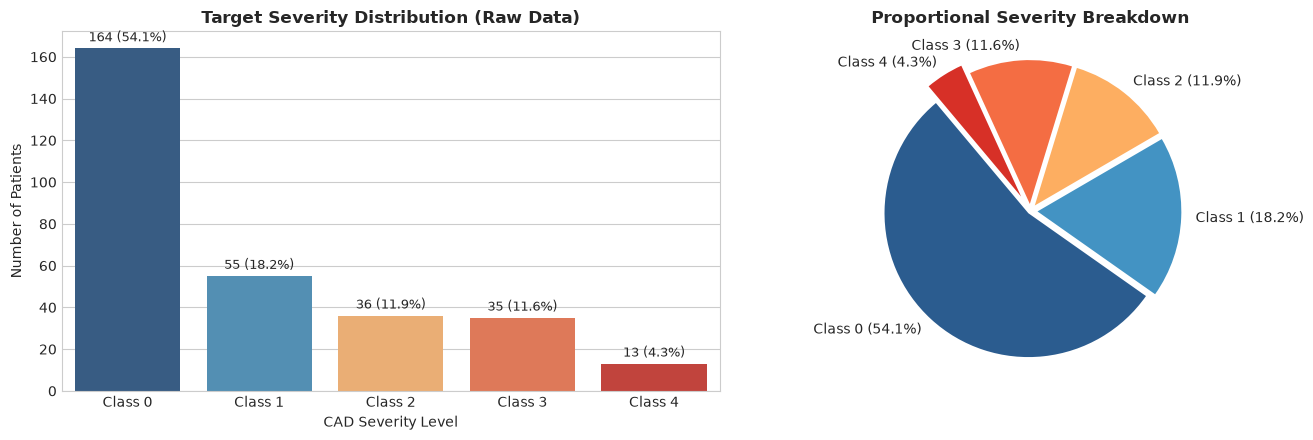

In [3]:
severity_labels = {
    0: 'Class 0: No Disease (<50% stenosis)',
    1: 'Class 1: Mild CAD (>50% in 1 vessel)',
    2: 'Class 2: Moderate CAD',
    3: 'Class 3: Severe CAD',
    4: 'Class 4: Critical CAD (Multi-vessel)'
}

counts = df_raw['target'].value_counts().sort_index()
pcts = df_raw['target'].value_counts(normalize=True).sort_index() * 100

dist_table = pd.DataFrame({
    'Severity Class': [f'Class {i}' for i in counts.index],
    'Clinical Description': [severity_labels[i] for i in counts.index],
    'Patient Count': counts.values,
    'Percentage (%)': pcts.round(2).values
})
display(dist_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
palette_severity = ['#2b5c8f', '#4393c3', '#fdae61', '#f46d43', '#d73027']

sns.barplot(x=[f'Class {i}' for i in counts.index], y=counts.values, hue=[f'Class {i}' for i in counts.index], palette=palette_severity, legend=False, ax=axes[0])
axes[0].set_title('Target Severity Distribution (Raw Data)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Patients')
axes[0].set_xlabel('CAD Severity Level')
for p in axes[0].patches:
    val = int(p.get_height())
    pct = p.get_height() / len(df_raw) * 100
    axes[0].annotate(f"{val} ({pct:.1f}%)", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

axes[1].pie(counts.values, labels=[f'Class {i} ({p:.1f}%)' for i, p in zip(counts.index, pcts)],
            colors=palette_severity, startangle=130, explode=[0.02, 0.05, 0.05, 0.05, 0.12])
axes[1].set_title('Proportional Severity Breakdown', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### 1.2 Missing Value Analysis (Before Preprocessing)
Checking raw missingness patterns across all features.

Features with Missing Values (Before Imputation):


,Missing Count,Percentage (%)
ca,4,1.32
thal,2,0.66


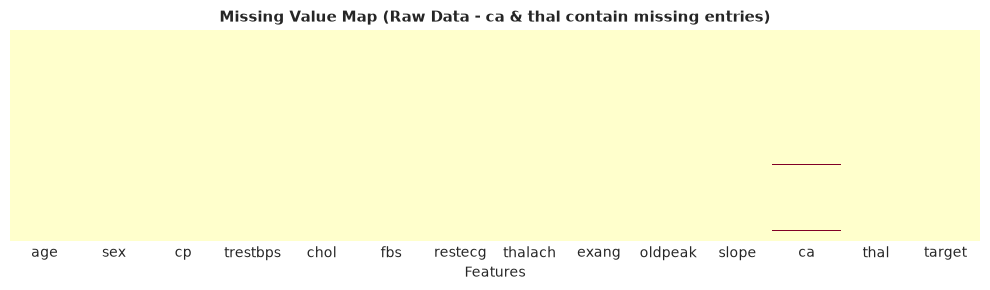

In [4]:
missing_counts = df_raw.isna().sum()
missing_cols = missing_counts[missing_counts > 0]

missing_df = pd.DataFrame({
    'Missing Count': missing_cols,
    'Percentage (%)': (missing_cols / len(df_raw) * 100).round(2)
})
print("Features with Missing Values (Before Imputation):")
display(missing_df)

# Missingness Heatmap
plt.figure(figsize=(10, 3))
sns.heatmap(df_raw.isna(), cbar=False, cmap='YlOrRd', yticklabels=False)
plt.title('Missing Value Map (Raw Data - ca & thal contain missing entries)', fontsize=11, fontweight='bold')
plt.xlabel('Features')
plt.show()

### 1.3 Continuous Feature Distributions & Severity Shifts (Before Preprocessing)
We evaluate the distribution and descriptive metrics (mean, std, IQR, skewness) of continuous clinical features before scaling, and analyze how they shift with CAD severity.

Descriptive Statistics of Continuous Features (Raw Scale):


,mean,std,min,25%,50%,75%,max,IQR,Skewness
age,54.44,9.04,29.0,48.0,56.0,61.0,77.0,13.0,-0.21
trestbps,131.69,17.60,94.0,120.0,130.0,140.0,200.0,20.0,0.71
chol,246.69,51.78,126.0,211.0,241.0,275.0,564.0,64.0,1.14
thalach,149.61,22.88,71.0,133.5,153.0,166.0,202.0,32.5,-0.54
oldpeak,1.04,1.16,0.0,0.0,0.8,1.6,6.2,1.6,1.27
ca,0.67,0.94,0.0,0.0,0.0,1.0,3.0,1.0,1.19


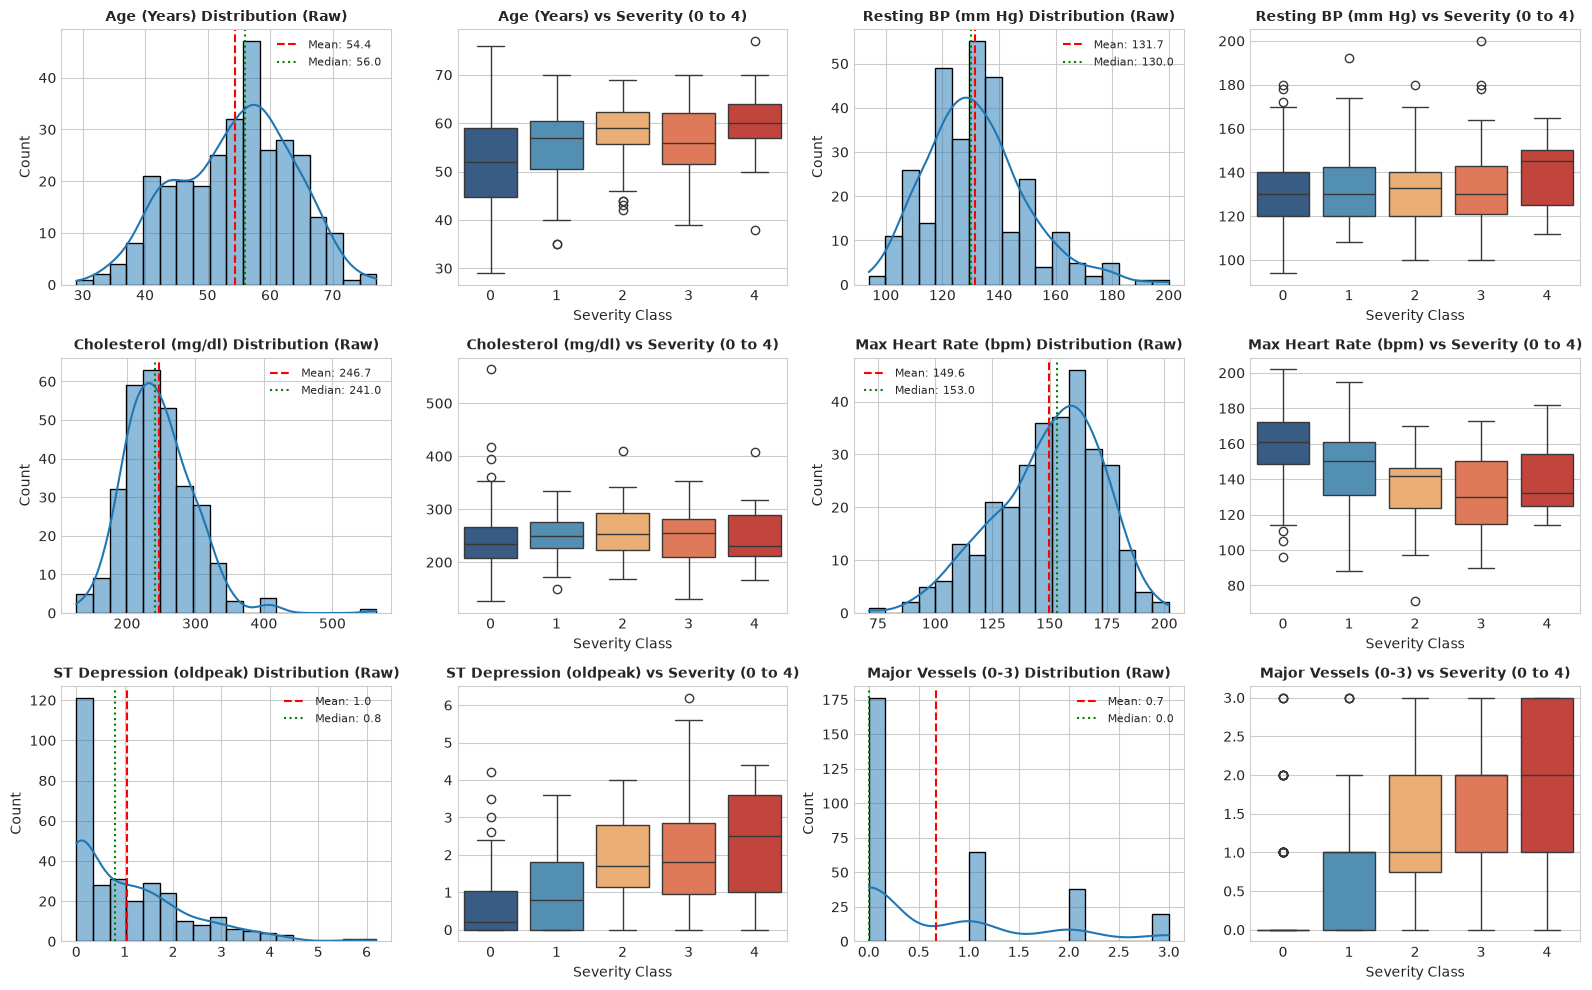

In [5]:
continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']

summary_raw = df_raw[continuous_cols].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
summary_raw['IQR'] = summary_raw['75%'] - summary_raw['25%']
summary_raw['Skewness'] = df_raw[continuous_cols].skew()
print("Descriptive Statistics of Continuous Features (Raw Scale):")
display(summary_raw.round(2))

# Histograms + Boxplots across severity
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

col_meta = {
    'age': 'Age (Years)',
    'trestbps': 'Resting BP (mm Hg)',
    'chol': 'Cholesterol (mg/dl)',
    'thalach': 'Max Heart Rate (bpm)',
    'oldpeak': 'ST Depression (oldpeak)',
    'ca': 'Major Vessels (0-3)'
}

for i, col in enumerate(continuous_cols):
    # Row 0/1/2 Left: Histogram + KDE
    ax_hist = axes[i // 2, (i % 2) * 2]
    sns.histplot(df_raw[col].dropna(), kde=True, ax=ax_hist, color='#1f77b4', bins=18)
    ax_hist.axvline(df_raw[col].mean(), color='red', linestyle='--', label=f"Mean: {df_raw[col].mean():.1f}")
    ax_hist.axvline(df_raw[col].median(), color='green', linestyle=':', label=f"Median: {df_raw[col].median():.1f}")
    ax_hist.set_title(f"{col_meta[col]} Distribution (Raw)", fontsize=10, fontweight='bold')
    ax_hist.set_xlabel('')
    ax_hist.legend(fontsize=8)
    
    # Row 0/1/2 Right: Boxplot by Severity Class
    ax_box = axes[i // 2, (i % 2) * 2 + 1]
    sns.boxplot(x='target', y=col, data=df_raw, hue='target', palette=palette_severity, legend=False, ax=ax_box)
    ax_box.set_title(f"{col_meta[col]} vs Severity (0 to 4)", fontsize=10, fontweight='bold')
    ax_box.set_xlabel('Severity Class')
    ax_box.set_ylabel('')

plt.tight_layout()
plt.show()

### 1.4 Categorical & Binary Features Analysis (Before Preprocessing)
Stacked composition charts showing how categorical conditions distribute across severity classes.

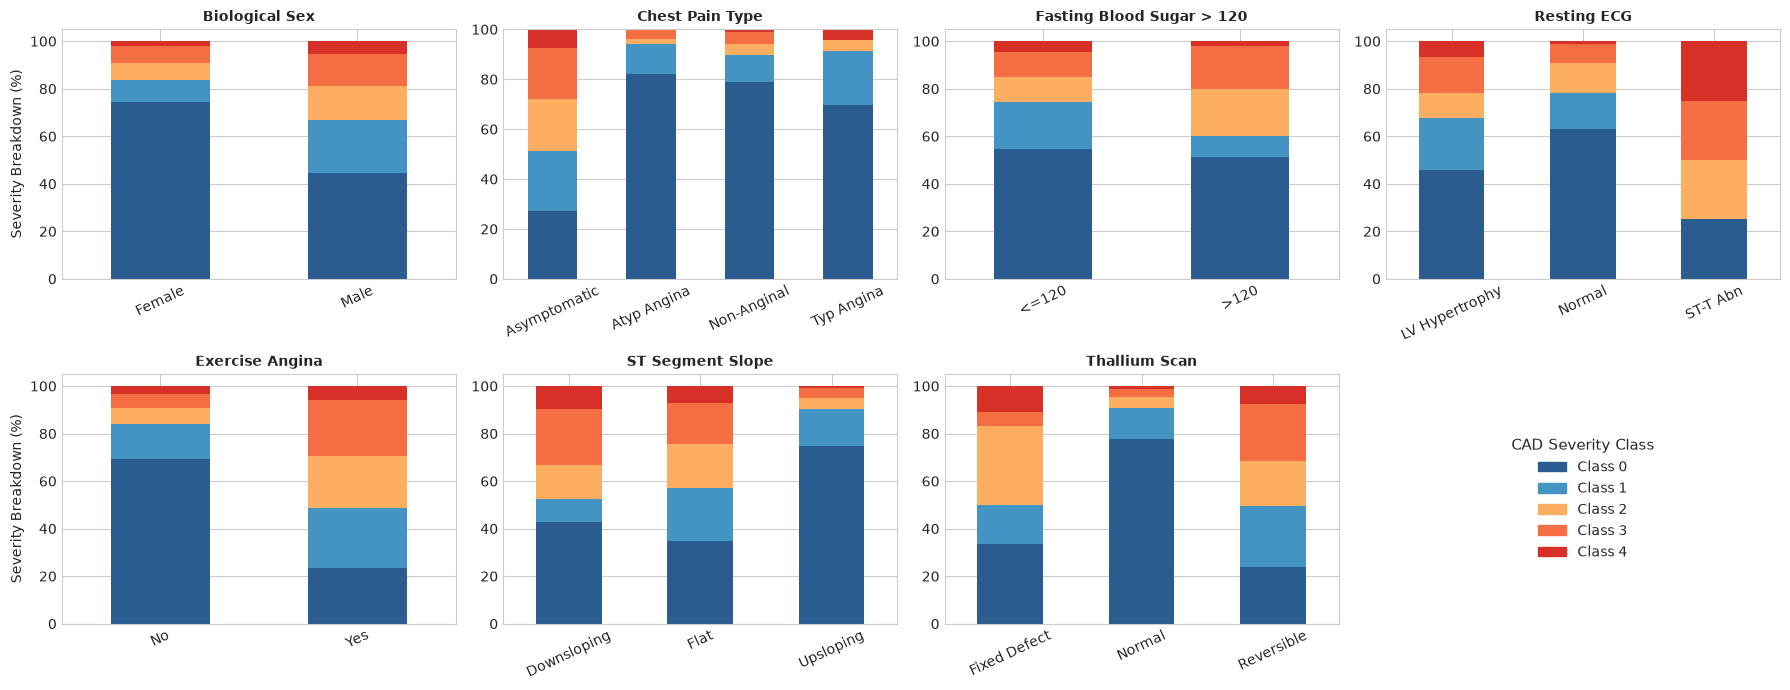

In [6]:
cat_meta = [
    ('sex', 'Biological Sex', {0: 'Female', 1: 'Male'}),
    ('cp', 'Chest Pain Type', {1: 'Typ Angina', 2: 'Atyp Angina', 3: 'Non-Anginal', 4: 'Asymptomatic'}),
    ('fbs', 'Fasting Blood Sugar > 120', {0: '<=120', 1: '>120'}),
    ('restecg', 'Resting ECG', {0: 'Normal', 1: 'ST-T Abn', 2: 'LV Hypertrophy'}),
    ('exang', 'Exercise Angina', {0: 'No', 1: 'Yes'}),
    ('slope', 'ST Segment Slope', {1: 'Upsloping', 2: 'Flat', 3: 'Downsloping'}),
    ('thal', 'Thallium Scan', {3: 'Normal', 6: 'Fixed Defect', 7: 'Reversible'})
]

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
axes = axes.flatten()

for idx, (col, title, lmap) in enumerate(cat_meta):
    ax = axes[idx]
    ct = pd.crosstab(df_raw[col].map(lmap), df_raw['target'], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, color=palette_severity, ax=ax, legend=False)
    ax.set_title(f"{title}", fontsize=10, fontweight='bold')
    ax.set_ylabel('Severity Breakdown (%)' if idx % 4 == 0 else '')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=25)

# Final subplot for legend
axes[-1].axis('off')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette_severity]
labels = [f'Class {i}' for i in range(5)]
axes[-1].legend(handles, labels, loc='center', title='CAD Severity Class', fontsize=10, title_fontsize=11)

plt.tight_layout()
plt.show()

### 1.5 Correlation Matrix (Before Preprocessing)
Pearson correlation matrix across raw clinical features.

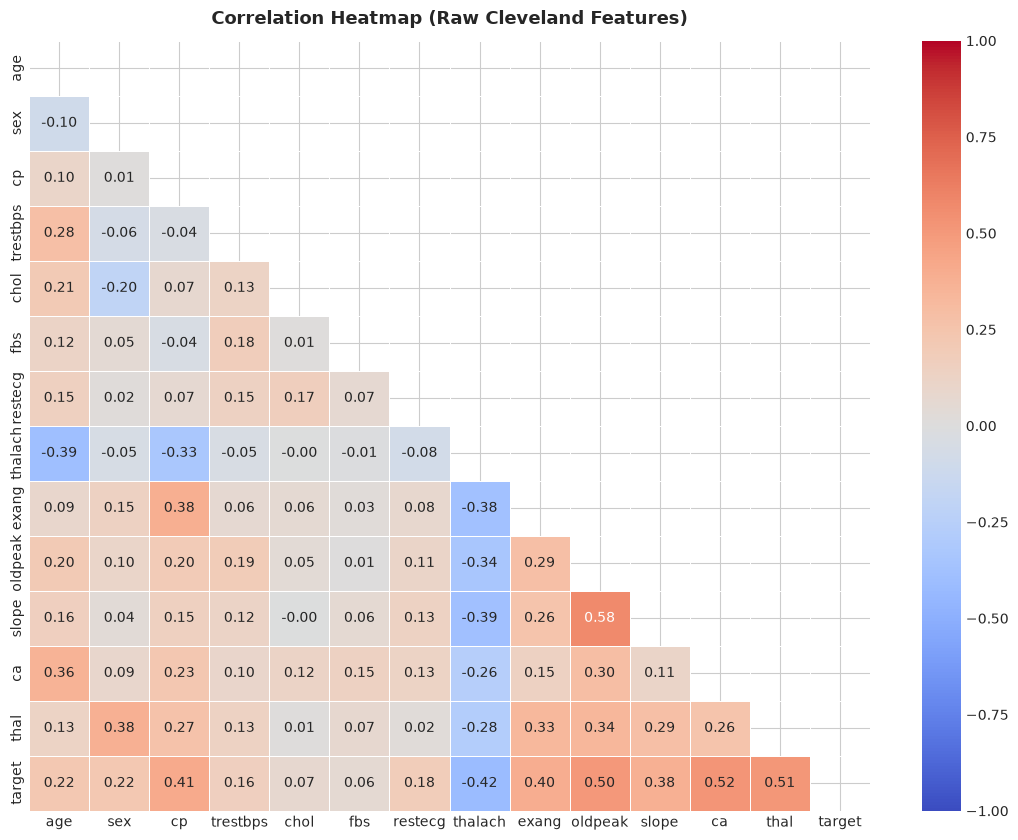

Top Correlations with CAD Severity (Raw Features):
ca              : +0.519
thal            : +0.510
oldpeak         : +0.504
cp              : +0.407
exang           : +0.397
slope           : +0.378
sex             : +0.224
age             : +0.223
restecg         : +0.184
trestbps        : +0.158
chol            : +0.071
fbs             : +0.059
thalach         : -0.415


In [7]:
plt.figure(figsize=(11, 8.5))
corr_raw = df_raw.corr()
mask = np.triu(np.ones_like(corr_raw, dtype=bool))

sns.heatmap(corr_raw, annot=True, fmt='.2f', cmap='coolwarm', mask=mask, vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap (Raw Cleveland Features)', fontsize=13, fontweight='bold', pad=12)
plt.show()

print("Top Correlations with CAD Severity (Raw Features):")
raw_target_corr = corr_raw['target'].drop('target').sort_values(ascending=False)
for feat, val in raw_target_corr.items():
    print(f"{feat:15s} : {val:+.3f}")

# PART 2: ZERO-LEAKAGE PREPROCESSING PIPELINE (NO SMOTE)

### Preprocessing Steps:
1. **Stratified 80/20 Train-Test Split**: Executed first to isolate the holdout test set.
2. **Median & Mode Imputation**: Fitted on `X_train`, applied to `X_train` and `X_test`.
3. **One-Hot Encoding**: Fitted on `X_train` for nominal features (`cp`, `restecg`, `slope`, `thal`).
4. **Min-Max Scaling**: Normalizes all 22 features to $[0, 1]$, fitted on `X_train`.
5. **Strictly NO SMOTE**: No synthetic samples are generated. `X_train` keeps its natural clinical sample count ($N=242$).

In [8]:
# Step 1: Feature-Target Separation & Stratified Split
X = df_raw.drop(columns=['target'])
y = df_raw['target'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print('=== STEP 1: STRATIFIED SPLIT (80/20) ===')
print(f"X_train shape: {X_train.shape} | y_train counts: {y_train.value_counts().sort_index().to_dict()}")
print(f"X_test shape:  {X_test.shape}  | y_test counts:  {y_test.value_counts().sort_index().to_dict()}")

# Feature groupings
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
cat_cols = ['cp', 'restecg', 'slope', 'thal']
bin_cols = ['sex', 'fbs', 'exang']

# Step 2: Leak-Free Missing Value Imputation
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

X_tr_num = pd.DataFrame(num_imputer.fit_transform(X_train[num_cols]), columns=num_cols, index=X_train.index)
X_te_num = pd.DataFrame(num_imputer.transform(X_test[num_cols]), columns=num_cols, index=X_test.index)

X_tr_cat_all = pd.DataFrame(cat_imputer.fit_transform(X_train[cat_cols + bin_cols]), columns=cat_cols + bin_cols, index=X_train.index)
X_te_cat_all = pd.DataFrame(cat_imputer.transform(X_test[cat_cols + bin_cols]), columns=cat_cols + bin_cols, index=X_test.index)

# Step 3: One-Hot Encoding for Nominal Categorical Predictors
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe_cols = ohe.fit(X_tr_cat_all[cat_cols]).get_feature_names_out(cat_cols)

X_tr_ohe = pd.DataFrame(ohe.transform(X_tr_cat_all[cat_cols]), columns=ohe_cols, index=X_train.index)
X_te_ohe = pd.DataFrame(ohe.transform(X_te_cat_all[cat_cols]), columns=ohe_cols, index=X_test.index)

# Combine numerical, binary, and one-hot features
X_tr_assembled = pd.concat([X_tr_num, X_tr_cat_all[bin_cols], X_tr_ohe], axis=1)
X_te_assembled = pd.concat([X_te_num, X_te_cat_all[bin_cols], X_te_ohe], axis=1)

# Step 4: Min-Max Normalization to [0, 1]
scaler = MinMaxScaler()
final_feature_names = X_tr_assembled.columns
X_train_processed = pd.DataFrame(scaler.fit_transform(X_tr_assembled), columns=final_feature_names, index=X_train.index)
X_test_processed = pd.DataFrame(scaler.transform(X_te_assembled), columns=final_feature_names, index=X_test.index)

# Step 5: NO SMOTE - Authentic training distribution preserved
print('\n' + '='*65)
print('PIPELINE COMPLETE (NO SMOTE APPLIED)')
print('='*65)
print(f"X_train final shape: {X_train_processed.shape} (242 genuine patient samples)")
print(f"X_test final shape:  {X_test_processed.shape} (61 genuine patient samples)")
print(f"Total Transformed Features: {len(final_feature_names)}")
print('Features List:', list(final_feature_names))
print(f"Train class counts (unmodified): {y_train.value_counts().sort_index().to_dict()}")

=== STEP 1: STRATIFIED SPLIT (80/20) ===
X_train shape: (242, 13) | y_train counts: {0: 131, 1: 44, 2: 29, 3: 28, 4: 10}
X_test shape:  (61, 13)  | y_test counts:  {0: 33, 1: 11, 2: 7, 3: 7, 4: 3}

PIPELINE COMPLETE (NO SMOTE APPLIED)
X_train final shape: (242, 22) (242 genuine patient samples)
X_test final shape:  (61, 22) (61 genuine patient samples)
Total Transformed Features: 22
Features List: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'sex', 'fbs', 'exang', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0']
Train class counts (unmodified): {0: 131, 1: 44, 2: 29, 3: 28, 4: 10}


# PART 3: DATA ANALYSIS & VISUALIZATION (AFTER PREPROCESSING)

Here we verify and visualize the preprocessed feature matrices: checking scale transformations, zero-missingness, preserved stratification, correlation shifts, and 2D latent space separability via PCA.

### 3.1 Feature Scaling Verification: Side-by-Side Distribution (Before vs After)
Comparing feature ranges before scaling vs after $[0, 1]$ Min-Max normalization to demonstrate preserved distribution geometry.

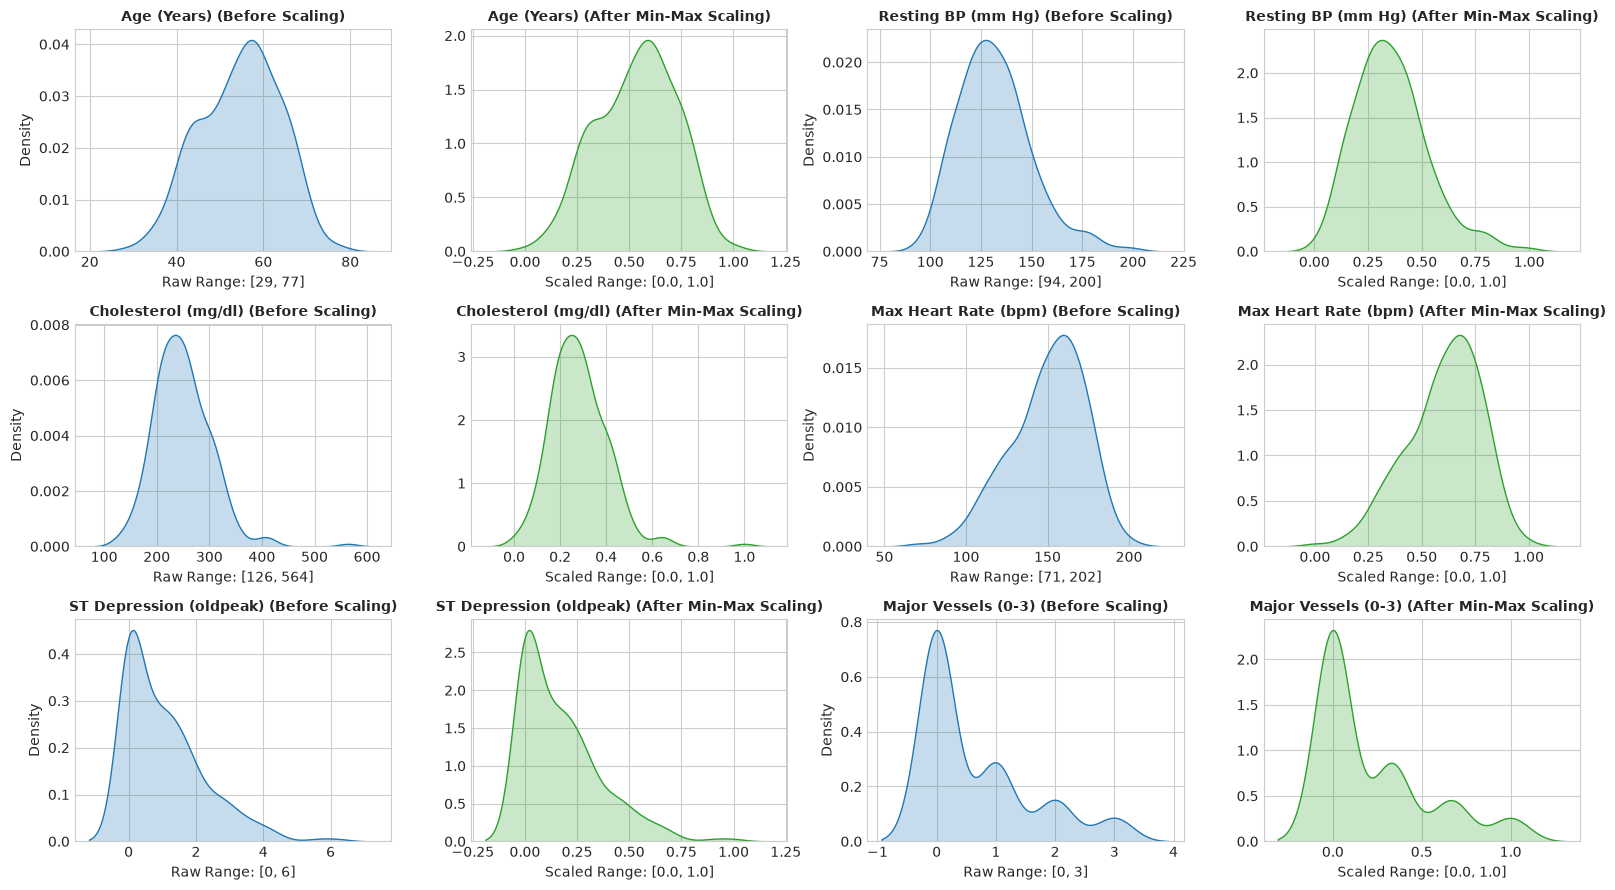

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))

for i, col in enumerate(continuous_cols):
    # Before Preprocessing (Train raw)
    ax_before = axes[i // 2, (i % 2) * 2]
    sns.kdeplot(X_train[col].dropna(), ax=ax_before, color='#1f77b4', fill=True)
    ax_before.set_title(f"{col_meta[col]} (Before Scaling)", fontsize=10, fontweight='bold')
    ax_before.set_xlabel(f"Raw Range: [{X_train[col].min():.0f}, {X_train[col].max():.0f}]")
    ax_before.set_ylabel('Density')
    
    # After Preprocessing (Train MinMax scaled [0, 1])
    ax_after = axes[i // 2, (i % 2) * 2 + 1]
    sns.kdeplot(X_train_processed[col], ax=ax_after, color='#2ca02c', fill=True)
    ax_after.set_title(f"{col_meta[col]} (After Min-Max Scaling)", fontsize=10, fontweight='bold')
    ax_after.set_xlabel('Scaled Range: [0.0, 1.0]')
    ax_after.set_ylabel('')

plt.tight_layout()
plt.show()

### 3.2 Missingness Resolution: Before vs After
Verifying that missing values have been completely resolved across both train and test splits.

In [10]:
imputation_check = pd.DataFrame({
    'Raw Missing (Total)': df_raw[['ca', 'thal']].isna().sum(),
    'Imputed Train Missing': [X_train_processed['ca'].isna().sum(), X_tr_cat_all['thal'].isna().sum()],
    'Imputed Test Missing': [X_test_processed['ca'].isna().sum(), X_te_cat_all['thal'].isna().sum()]
}, index=['ca (Major Vessels)', 'thal (Thallium Scan)'])
print("Imputation Verification Table (Before vs After):")
display(imputation_check)
print(f"Total NaNs in X_train_processed: {X_train_processed.isna().sum().sum()}")
print(f"Total NaNs in X_test_processed:  {X_test_processed.isna().sum().sum()}")
assert X_train_processed.isna().sum().sum() == 0, 'Train contains NaNs!'
assert X_test_processed.isna().sum().sum() == 0, 'Test contains NaNs!'
print('[[OK]] Zero missing values confirmed across all preprocessed feature matrices.')

Imputation Verification Table (Before vs After):


,Raw Missing (Total),Imputed Train Missing,Imputed Test Missing
ca (Major Vessels),NaN,0,0
thal (Thallium Scan),NaN,0,0


Total NaNs in X_train_processed: 0
Total NaNs in X_test_processed:  0
[[OK]] Zero missing values confirmed across all preprocessed feature matrices.


### 3.3 Stratification Consistency: Train vs Test Splits
Verifying that the 5-class target proportions are identical between Train and Test sets without SMOTE distortion.

,Train Count,Train %,Test Count,Test %
target,,,,
0,131,54.13,33,54.10
1,44,18.18,11,18.03
2,29,11.98,7,11.48
3,28,11.57,7,11.48
4,10,4.13,3,4.92


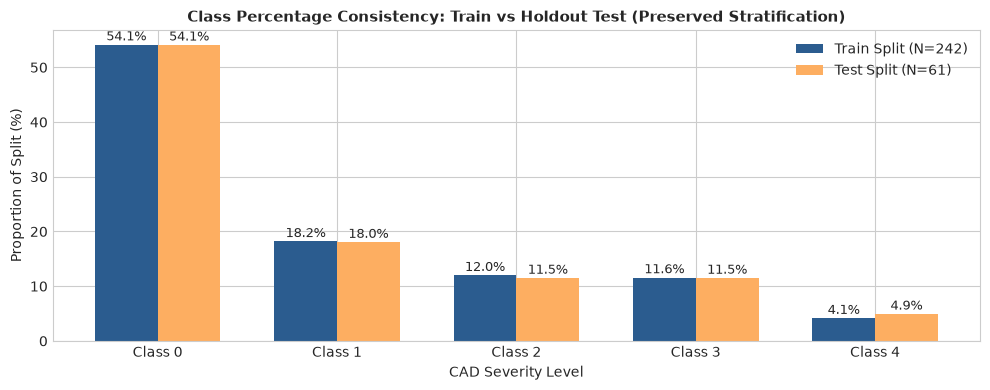

In [11]:
train_pcts = y_train.value_counts(normalize=True).sort_index() * 100
test_pcts = y_test.value_counts(normalize=True).sort_index() * 100

strat_df = pd.DataFrame({
    'Train Count': y_train.value_counts().sort_index(),
    'Train %': train_pcts.round(2),
    'Test Count': y_test.value_counts().sort_index(),
    'Test %': test_pcts.round(2)
})
display(strat_df)

fig, ax = plt.subplots(figsize=(10, 4))
x_indices = np.arange(5)
width = 0.35

ax.bar(x_indices - width/2, train_pcts, width, label='Train Split (N=242)', color='#2b5c8f')
ax.bar(x_indices + width/2, test_pcts, width, label='Test Split (N=61)', color='#fdae61')
ax.set_title('Class Percentage Consistency: Train vs Holdout Test (Preserved Stratification)', fontsize=11, fontweight='bold')
ax.set_xlabel('CAD Severity Level')
ax.set_ylabel('Proportion of Split (%)')
ax.set_xticks(x_indices)
ax.set_xticklabels([f'Class {i}' for i in range(5)])
ax.legend()
for i in x_indices:
    ax.annotate(f"{train_pcts[i]:.1f}%", (i - width/2, train_pcts[i] + 0.8), ha='center', fontsize=9)
    ax.annotate(f"{test_pcts[i]:.1f}%", (i + width/2, test_pcts[i] + 0.8), ha='center', fontsize=9)
plt.tight_layout()
plt.show()

### 3.4 Correlation Analysis Across All 22 Transformed Features (After Preprocessing)
Correlations of one-hot encoded and normalized continuous predictors against the multi-class target.

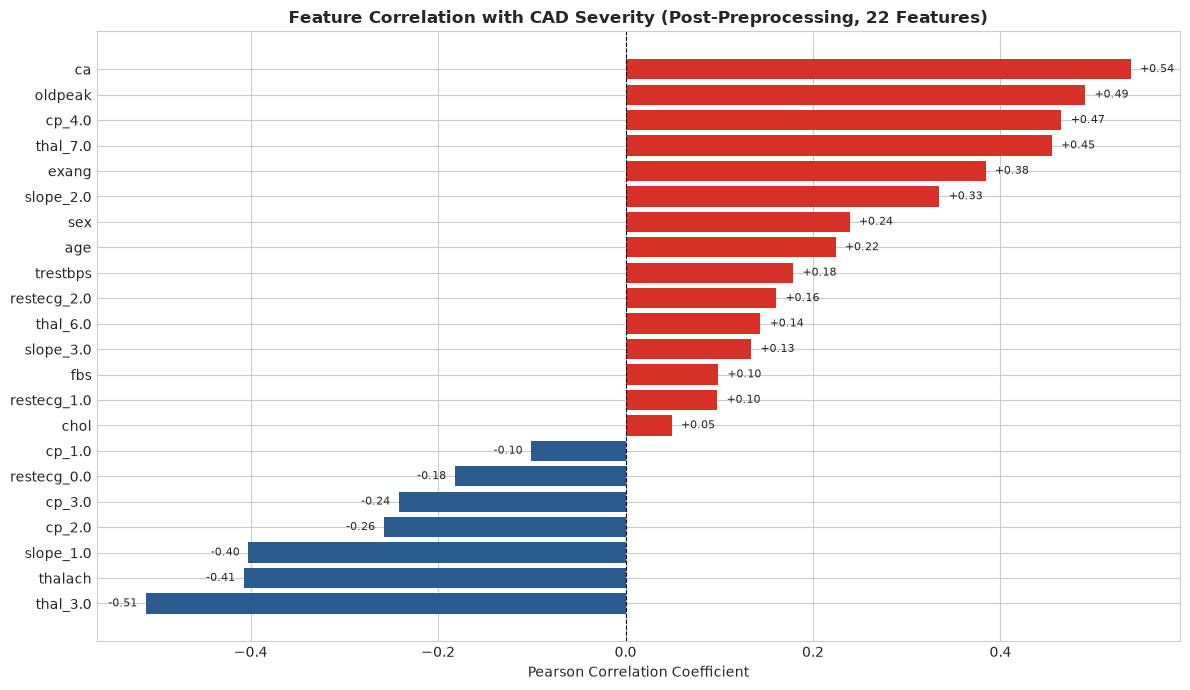

In [12]:
train_full = X_train_processed.copy()
train_full['target'] = y_train.values

corr_post = train_full.corr()
target_corrs_post = corr_post['target'].drop('target').sort_values()

plt.figure(figsize=(12, 7))
colors = ['#d73027' if v > 0 else '#2b5c8f' for v in target_corrs_post.values]
plt.barh(target_corrs_post.index, target_corrs_post.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Feature Correlation with CAD Severity (Post-Preprocessing, 22 Features)', fontsize=12, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient')
for i, v in enumerate(target_corrs_post.values):
    plt.annotate(f"{v:+.2f}", (v + (0.01 if v > 0 else -0.04), i), va='center', fontsize=8)
plt.tight_layout()
plt.show()

### 3.5 Latent Feature Space & Class Separability (PCA 2D Projection)
Visualizing patient clusters in the 22-dimensional transformed space using 2-component Principal Component Analysis (PCA).

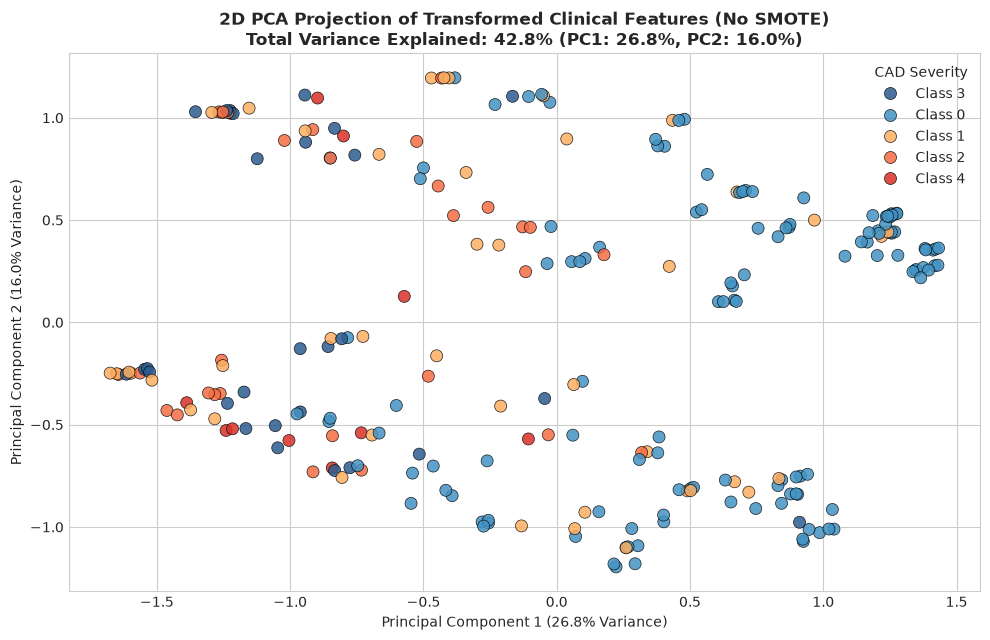

In [13]:
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_processed)

pca_df = pd.DataFrame({
    'PC1': X_train_pca[:, 0],
    'PC2': X_train_pca[:, 1],
    'Severity Class': [f'Class {i}' for i in y_train.values]
})

plt.figure(figsize=(10, 6.5))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Severity Class',
    palette=palette_severity,
    s=75,
    alpha=0.85,
    edgecolor='black',
    linewidth=0.5
)
var_exp = pca.explained_variance_ratio_ * 100
plt.title(f'2D PCA Projection of Transformed Clinical Features (No SMOTE)\nTotal Variance Explained: {var_exp.sum():.1f}% (PC1: {var_exp[0]:.1f}%, PC2: {var_exp[1]:.1f}%)',
          fontsize=12, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({var_exp[0]:.1f}% Variance)')
plt.ylabel(f'Principal Component 2 ({var_exp[1]:.1f}% Variance)')
plt.legend(title='CAD Severity', loc='best')
plt.tight_layout()
plt.show()

## 4. Comprehensive Comparison Table (Before vs After Preprocessing)

| Attribute / Metric | Before Preprocessing (Raw Data) | After Preprocessing (No SMOTE Pipeline) |
|:---|:---|:---|
| **Total Instances** | 303 patients | **Train**: 242 patients, **Holdout Test**: 61 patients |
| **Feature Dimensionality** | 13 predictors + 1 target | **22 predictors** (One-Hot Encoded) + 1 target |
| **Target Encoding** | Raw integers (0, 1, 2, 3, 4) | Preserved 5-class clinical severity (0 to 4) |
| **Feature Value Scales** | Widely disparate: `chol` [126, 564], `oldpeak` [0, 6.2] | **All features normalized to $[0, 1]$** via Min-Max |
| **Missing Values** | 6 total (`ca`: 4, `thal`: 2) | **0 missing values** (Leak-free Median/Mode Imputed) |
| **Oversampling (SMOTE)** | None | **None** (Natural authentic distribution preserved) |
| **Class Balance (Train)** | {0: 164, 1: 55, 2: 36, 3: 35, 4: 13} | **{0: 131, 1: 44, 2: 29, 3: 28, 4: 10}** (Authentic) |
| **Data Leakage Risk** | High if transformed globally | **Zero** (Imputers, Encoders, Scaler fitted on Train only) |

### Matrices Available for Model Training:
- `X_train_processed`: DataFrame of shape `(242, 22)`
- `y_train`: Series of length `242`
- `X_test_processed`: DataFrame of shape `(61, 22)`
- `y_test`: Series of length `61`